# 08 - Humidade do solo e hidrometeorologia: ERA5-Land e SMAP

| | |
|---|---|
| **Tarefa do plano** | Humidade do solo da Camada 1 para os 20 anos + reforço SMAP (verificação de sobreposição e correção de viés na semana 2) |
| **Variáveis (Parte I)** | #28 água no solo camadas 1-2, #29 escoamento superficial, #30 temperatura e evaporação, #31 SMAP superficial, #32 SMAP zona radicular |
| **Fonte** | Agregados diários ERA5-Land (ECMWF) e SMAP L4 (NASA), via Earth Engine |
| **Saída** | `data/raw/hydromet/` |

Valores diários sobre toda a bacia, na grelha nativa de cada produto. ERA5-Land: um NetCDF por variável e por ano. O SMAP é de 3 em 3 horas na fonte: cada dia é a média do dia UTC, um NetCDF por variável e por mês.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## 1. ERA5-Land (2006-2026)

In [2]:
era = cfg["datasets"]["era5_land"]
UNITS = {"volumetric_soil_water_layer_1": "m3/m3", "volumetric_soil_water_layer_2": "m3/m3",
         "surface_runoff_sum": "m/day", "temperature_2m": "K", "total_evaporation_sum": "m/day"}
era_grid = gee.collection_grid(ee.ImageCollection(era["id"]), era["bands"][0], climate_bounds, fallback_res=0.1)
print(era_grid)

for band in era["bands"]:
    log = gee.download_daily_netcdf(cfg, "era5land", era["id"], band, era_grid, config.path(cfg, "era5_land"),
                                    start=era["start"], freq="YS", units=UNITS.get(band, ""))
    print(band, log["status"].value_counts().to_dict())

Grid(crs='EPSG:4326', res=0.1, x0=29.44999999999999, y0=-23.750000000000014, width=40, height=29)


era5land:volumetric_soil_water_layer_1:   0%|          | 0/21 [00:00<?, ?it/s]

volumetric_soil_water_layer_1 {'downloaded': 21}


era5land:volumetric_soil_water_layer_2:   0%|          | 0/21 [00:00<?, ?it/s]

volumetric_soil_water_layer_2 {'downloaded': 21}


era5land:surface_runoff_sum:   0%|          | 0/21 [00:00<?, ?it/s]

surface_runoff_sum {'downloaded': 21}


era5land:temperature_2m:   0%|          | 0/21 [00:00<?, ?it/s]

temperature_2m {'downloaded': 21}


era5land:total_evaporation_sum:   0%|          | 0/21 [00:00<?, ?it/s]

total_evaporation_sum {'downloaded': 21}


## 2. SMAP L4 (2015-2026)

In [2]:
smap = cfg["datasets"]["smap"]
smap_grid = gee.collection_grid(ee.ImageCollection(smap["id"]), smap["bands"][0], climate_bounds, fallback_res=0.1)
print(smap_grid)

for band in smap["bands"]:
    log = gee.download_daily_netcdf(cfg, "smap", smap["id"], band, smap_grid, config.path(cfg, "smap"),
                                    start=smap["start"], freq="MS", units="m3/m3")
    print(band, log["status"].value_counts().to_dict())

/home/miocha/all_information/Projecto-ETE/.venv/lib/python3.14/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for NASA/SMAP/SPL4SMGP/007! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by NASA/SMAP/SPL4SMGP/008

Learn more: https://developers.google.com/earth-engine/datasets/catalog/NASA_SMAP_SPL4SMGP_007

  warnings.warn(warning, category=DeprecationWarning)


Grid(crs='EPSG:4326', res=0.09516149300142837, x0=29.545607639294076, y0=-23.820246114068567, width=41, height=30)


smap:sm_surface:   0%|          | 0/138 [00:00<?, ?it/s]

sm_surface {'downloaded': 79, 'exists': 44, 'absent': 15}


smap:sm_rootzone:   0%|          | 0/138 [00:00<?, ?it/s]

sm_rootzone {'downloaded': 123, 'absent': 15}


## 3. Controlo de qualidade

ERA5-Land dias em falta: 0 | SMAP dias em falta: 0


<Axes: title={'center': 'Humidade superficial do solo, média da bacia (dados brutos, antes da correção de viés)'}, xlabel='time', ylabel='m3/m3'>

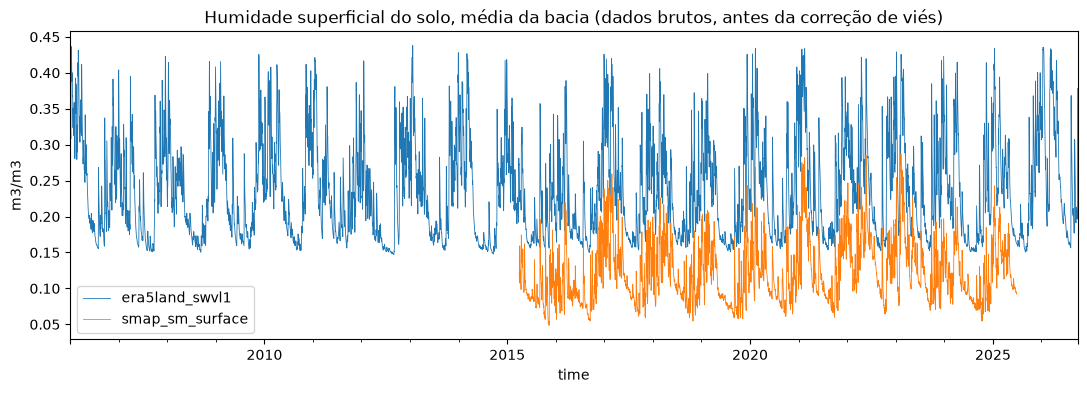

In [3]:
basin = G.load_aoi(cfg, "basin")
era_sm = series.open_series(cfg, "era5_land", "volumetric_soil_water_layer_1")
smap_sm = series.open_series(cfg, "smap", "sm_surface")
print("ERA5-Land dias em falta:", len(series.missing_days(era_sm)), "| SMAP dias em falta:", len(series.missing_days(smap_sm)))

moisture = pd.DataFrame({"era5land_swvl1": series.area_mean(era_sm, basin),
                         "smap_sm_surface": series.area_mean(smap_sm, basin)})
csv = config.path(cfg, "interim", "hydromet", "soil_moisture_daily_basin_mean.csv")
moisture.to_csv(csv, index_label="date")
moisture.plot(figsize=(13, 4), linewidth=0.6, ylabel="m3/m3", title="Humidade superficial do solo, média da bacia (dados brutos, antes da correção de viés)")